In [1]:
import pandas as pd
import numpy as np
import seaborn as sns # a ploting library based on matplotlib
import matplotlib.pyplot as plt

# K-Means Clustering (Task C)
**Goal:** discover natural booking/customer segments in the City Hotel (H2) data.  
The task is fully **unsupervised**: the model never sees `IsCanceled` or any other outcome column.  
Clusters are evaluated with internal measures only (Inertia, Silhouette Score, Davies-Bouldin Index).

# Preprocessing
Same cleaning steps as the classification notebook.

In [2]:
df = pd.read_csv("../data/raw/H2.csv", na_values=['NULL'], skipinitialspace=True)
df.shape

(79330, 31)

### Removing invalid / undefined rows

In [3]:
df = df[df["MarketSegment"] != "Undefined"]
df = df[df["DistributionChannel"] != "Undefined"]
df = df[df["Adults"] > 0]   # also removes children/babies with no adult
df["Children"] = df["Children"].fillna(0)
df["Country"] = df["Country"].fillna("Unknown")
df.shape

(78936, 31)

### ADR outlier
One booking has an ADR of 5400, far above every other value. K-Means uses distances, so a single extreme point can pull a centroid, so it is removed.

In [4]:
df["ADR"].describe()

count    78936.000000
mean       105.575784
std         43.404182
min          0.000000
25%         79.200000
50%        100.000000
75%        126.000000
max       5400.000000
Name: ADR, dtype: float64

In [5]:
df = df[df["ADR"] < 1000]
df["ADR"].describe()

count    78935.000000
mean       105.508710
std         39.100176
min          0.000000
25%         79.200000
50%        100.000000
75%        126.000000
max        510.000000
Name: ADR, dtype: float64

### Derived features

In [6]:
df["TotalNights"] = df["StaysInWeekendNights"] + df["StaysInWeekNights"]
df["TotalGuests"] = df["Adults"] + df["Children"] + df["Babies"]

## Feature Selection and Leakage Check
Clusters should describe a booking **as it looks when it is made**, so columns that encode a final outcome or something that happens later are excluded:

| Excluded column | Reason |
|---|---|
| `IsCanceled` | the outcome (classification target) |
| `ReservationStatus`, `ReservationStatusDate` | final status of the booking, directly reveals cancellation |
| `AssignedRoomType` | decided at check-in, after the booking |
| `BookingChanges` | keeps growing until check-in or cancellation |
| `Agent`, `Company` | ID numbers, distances between IDs mean nothing |
| `ArrivalDate*`, `Country` | many categories, would dominate the distances |

**Selected features**

| Feature | Type | Why |
|---|---|---|
| `LeadTime` | numeric | how early the guest plans |
| `TotalNights` | numeric | length of stay |
| `ADR` | numeric | price paid per night |
| `TotalGuests` | numeric | group size |
| `TotalOfSpecialRequests` | numeric | how engaged / demanding the guest is |
| `MarketSegment` | categorical | how the booking was sold (Online TA, Groups, Corporate, ...) |

In [7]:
num_cols = ["LeadTime", "TotalNights", "ADR", "TotalGuests", "TotalOfSpecialRequests"]
cat_cols = ["MarketSegment"]

df_clust = df[num_cols + cat_cols].copy()
df_clust.describe().T

,count,mean,std,min,25%,50%,75%,max
LeadTime,78935.0,109.848420,111.001569,0.0,23.0,74.0,164.0,629.0
TotalNights,78935.0,2.973307,1.825566,0.0,2.0,3.0,4.0,48.0
ADR,78935.0,105.508710,39.100176,0.0,79.2,100.0,126.0,510.0
TotalGuests,78935.0,1.951112,0.631701,1.0,2.0,2.0,2.0,12.0
TotalOfSpecialRequests,78935.0,0.545588,0.780035,0.0,0.0,0.0,1.0,5.0


## Visuals and Plots
### Skewness
K-Means uses distances, so long right tails stretch the feature space. Skewness above about 1 is treated as strong.  
`LeadTime` and `TotalNights` are strongly skewed, so they get a `log1p` transform ($\log(1+x)$, which also handles zeros).  
`ADR` is only mildly skewed and has zero-price bookings, which a log would turn into extreme low outliers, so it is left as is.

LeadTime                  1.390809
TotalNights               3.384679
ADR                       0.851310
TotalGuests               0.785641
TotalOfSpecialRequests    1.406605
dtype: float64


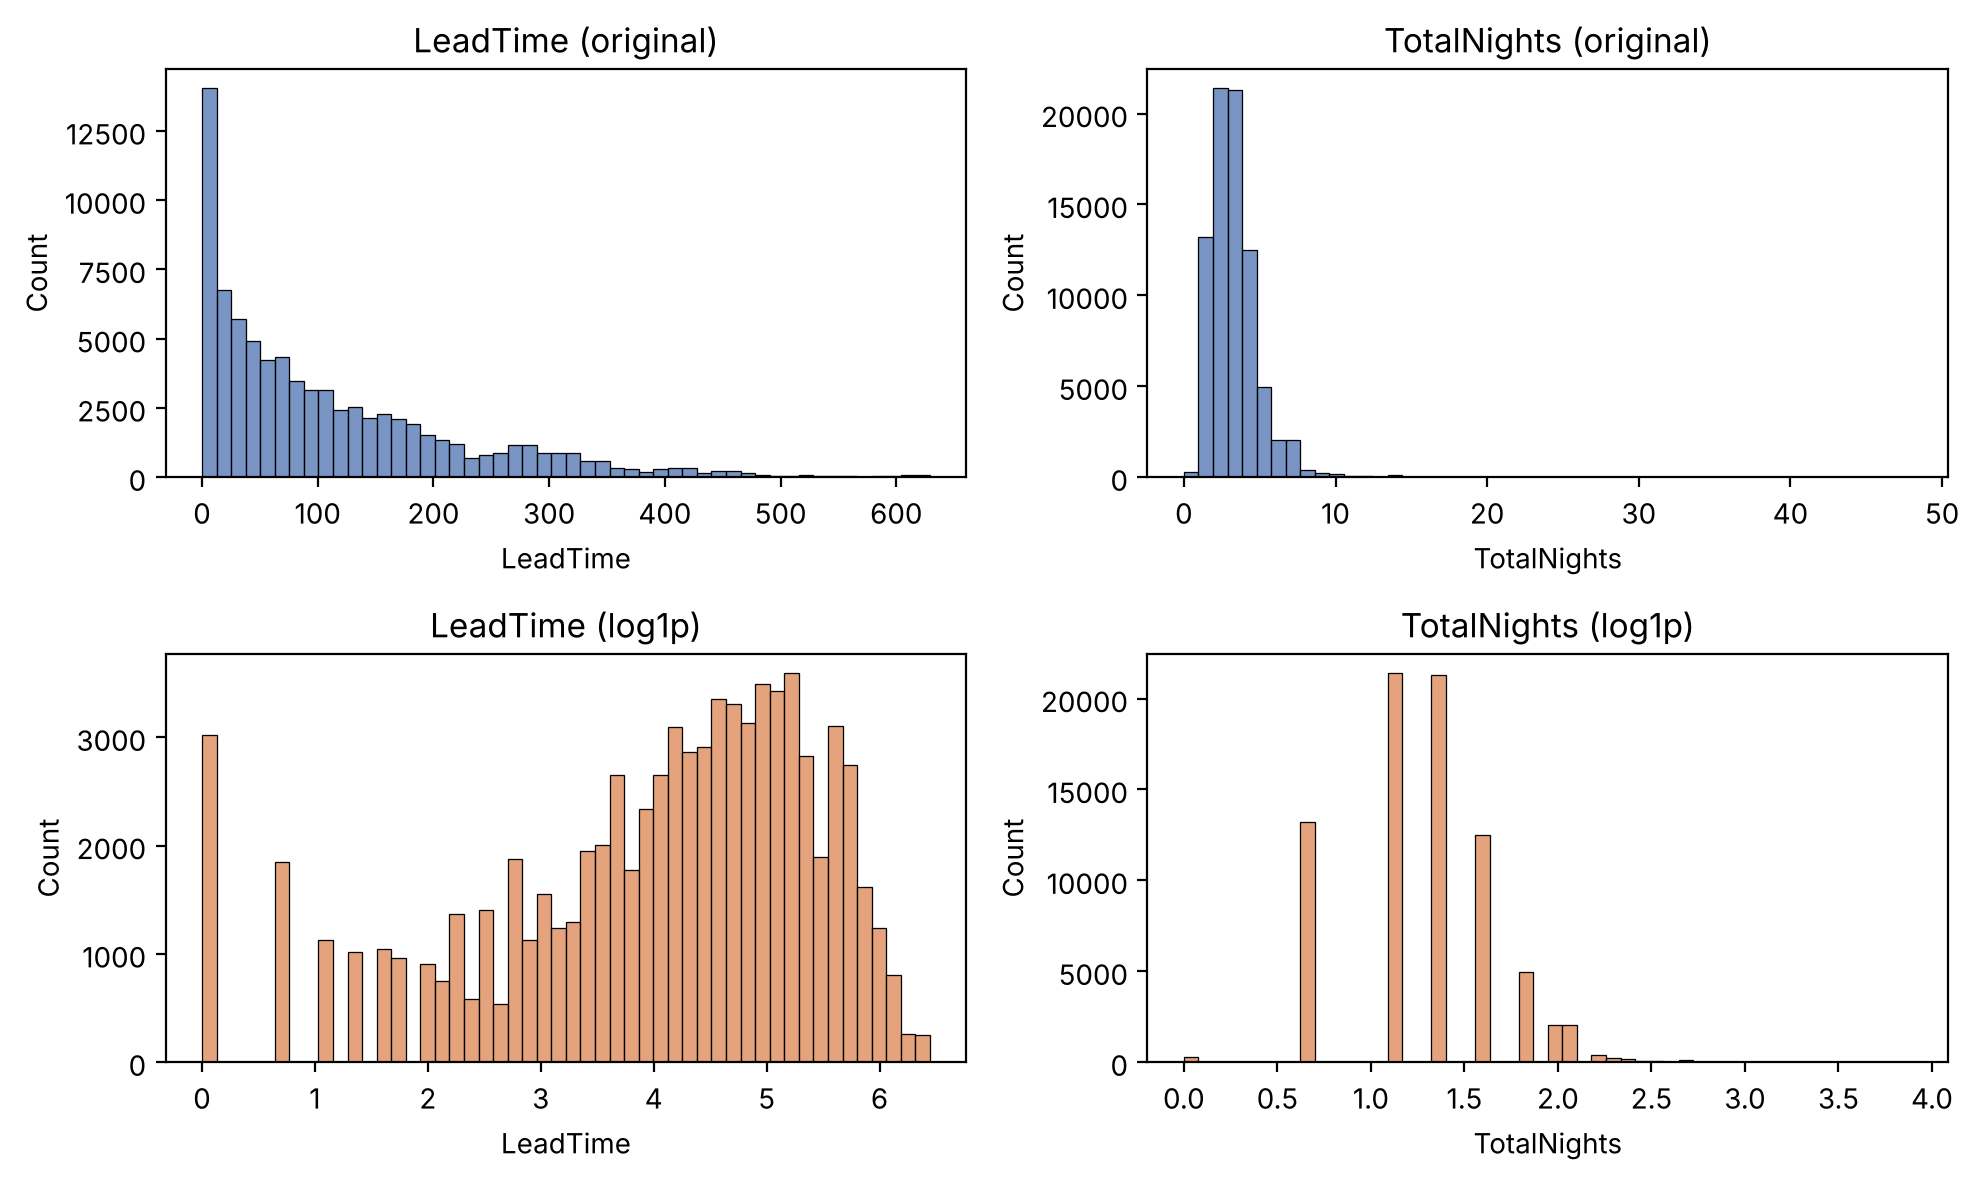

In [8]:
print(df_clust[num_cols].skew())

skewed = ["LeadTime", "TotalNights"]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for i, c in enumerate(skewed):
    sns.histplot(df_clust[c], bins=50, ax=axes[0, i], color="#4C72B0")
    axes[0, i].set_title(f"{c} (original)")
    sns.histplot(np.log1p(df_clust[c]), bins=50, ax=axes[1, i], color="#DD8452")
    axes[1, i].set_title(f"{c} (log1p)")
plt.tight_layout()
plt.show()

In [9]:
for c in skewed:
    df_clust[c] = np.log1p(df_clust[c])

print(df_clust[skewed].skew())

LeadTime      -0.934947
TotalNights    0.219276
dtype: float64


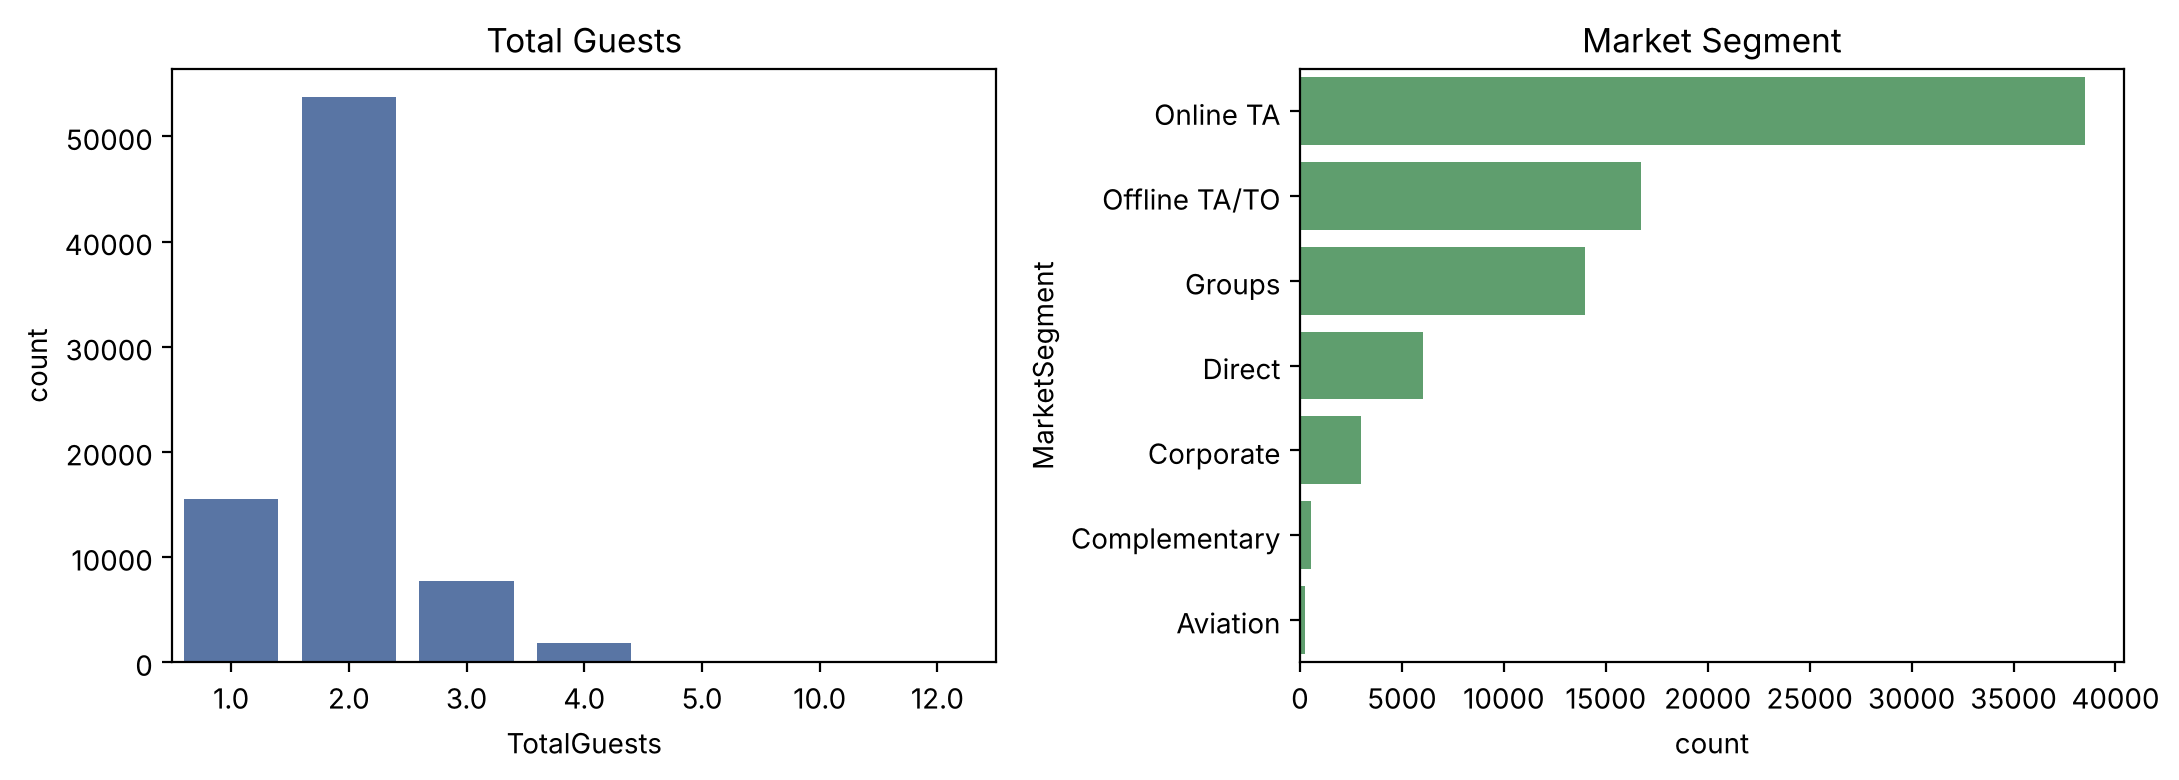

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df_clust, x="TotalGuests", ax=axes[0], color="#4C72B0")
axes[0].set_title("Total Guests")
sns.countplot(data=df_clust, y="MarketSegment", ax=axes[1], color="#55A868",
              order=df_clust["MarketSegment"].value_counts().index)
axes[1].set_title("Market Segment")
plt.tight_layout()
plt.show()

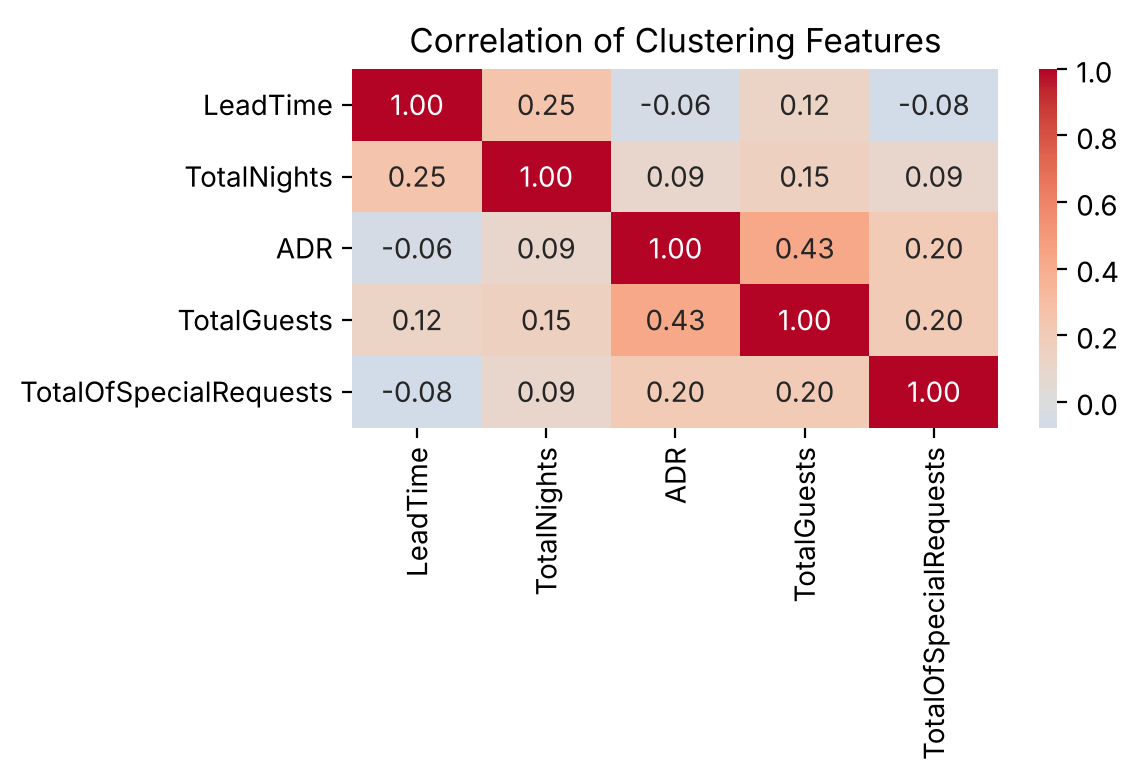

In [11]:
plt.figure(figsize=(6, 4))
sns.heatmap(df_clust[num_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation of Clustering Features")
plt.tight_layout()
plt.show()

## Encoding and Scaling
- Numeric features: `StandardScaler` so every feature has the same weight in the distance.
- `MarketSegment`: `OneHotEncoder` (K-Means cannot use text).

In [12]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

In [13]:
processor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

X = processor.fit_transform(df_clust)
X.shape

(78935, 12)

## Evaluation Metrics
- **Inertia**: sum of squared distances to the nearest centroid (lower is tighter).
- **Silhouette Score**: from -1 to 1, higher means points are closer to their own cluster than to others.
- **Davies-Bouldin Index**: lower is better, measures how similar each cluster is to its closest neighbour.

Silhouette is $O(n^2)$, so it is computed on a random sample of 10,000 rows (`sample_size`). K-Means itself is trained on the **full** dataset.

In [14]:
def evaluate(X, labels):
    sil = silhouette_score(X, labels, sample_size=10000, random_state=42)
    db = davies_bouldin_score(X, labels)
    return sil, db

## Baseline K-Means (Milestone 1)
Milestone 1 only needs an initial **untuned** experiment, so K-Means is run with scikit-learn's default settings (`n_clusters=8`, `init='k-means++'`, `n_init='auto'`). Only the random seed is fixed for reproducibility.  
Choosing the number of clusters (elbow, Silhouette, Davies-Bouldin search) is left for the tuning stage in Milestone 2.

In [15]:
kmeans = KMeans(random_state=42)
kmeans.fit(X)

sil, db = evaluate(X, kmeans.labels_)
print("Number of clusters:", kmeans.n_clusters)
print("Inertia:", round(kmeans.inertia_, 1))
print("Silhouette:", round(sil, 4))
print("Davies-Bouldin:", round(db, 4))

Number of clusters: 8
Inertia: 211656.9
Silhouette: 0.1804
Davies-Bouldin: 1.5887


In [16]:
df_clust["Cluster"] = kmeans.labels_
df_clust["Cluster"].value_counts().sort_index()

Cluster
0    12090
1    17489
2     7918
3     6715
4    12649
5     6099
6     7215
7     8760
Name: count, dtype: int64

## 2D Visualization with PCA
PCA projects the scaled features onto the 2 directions with the most variance, only for plotting.

Explained variance by 2 components: 0.527


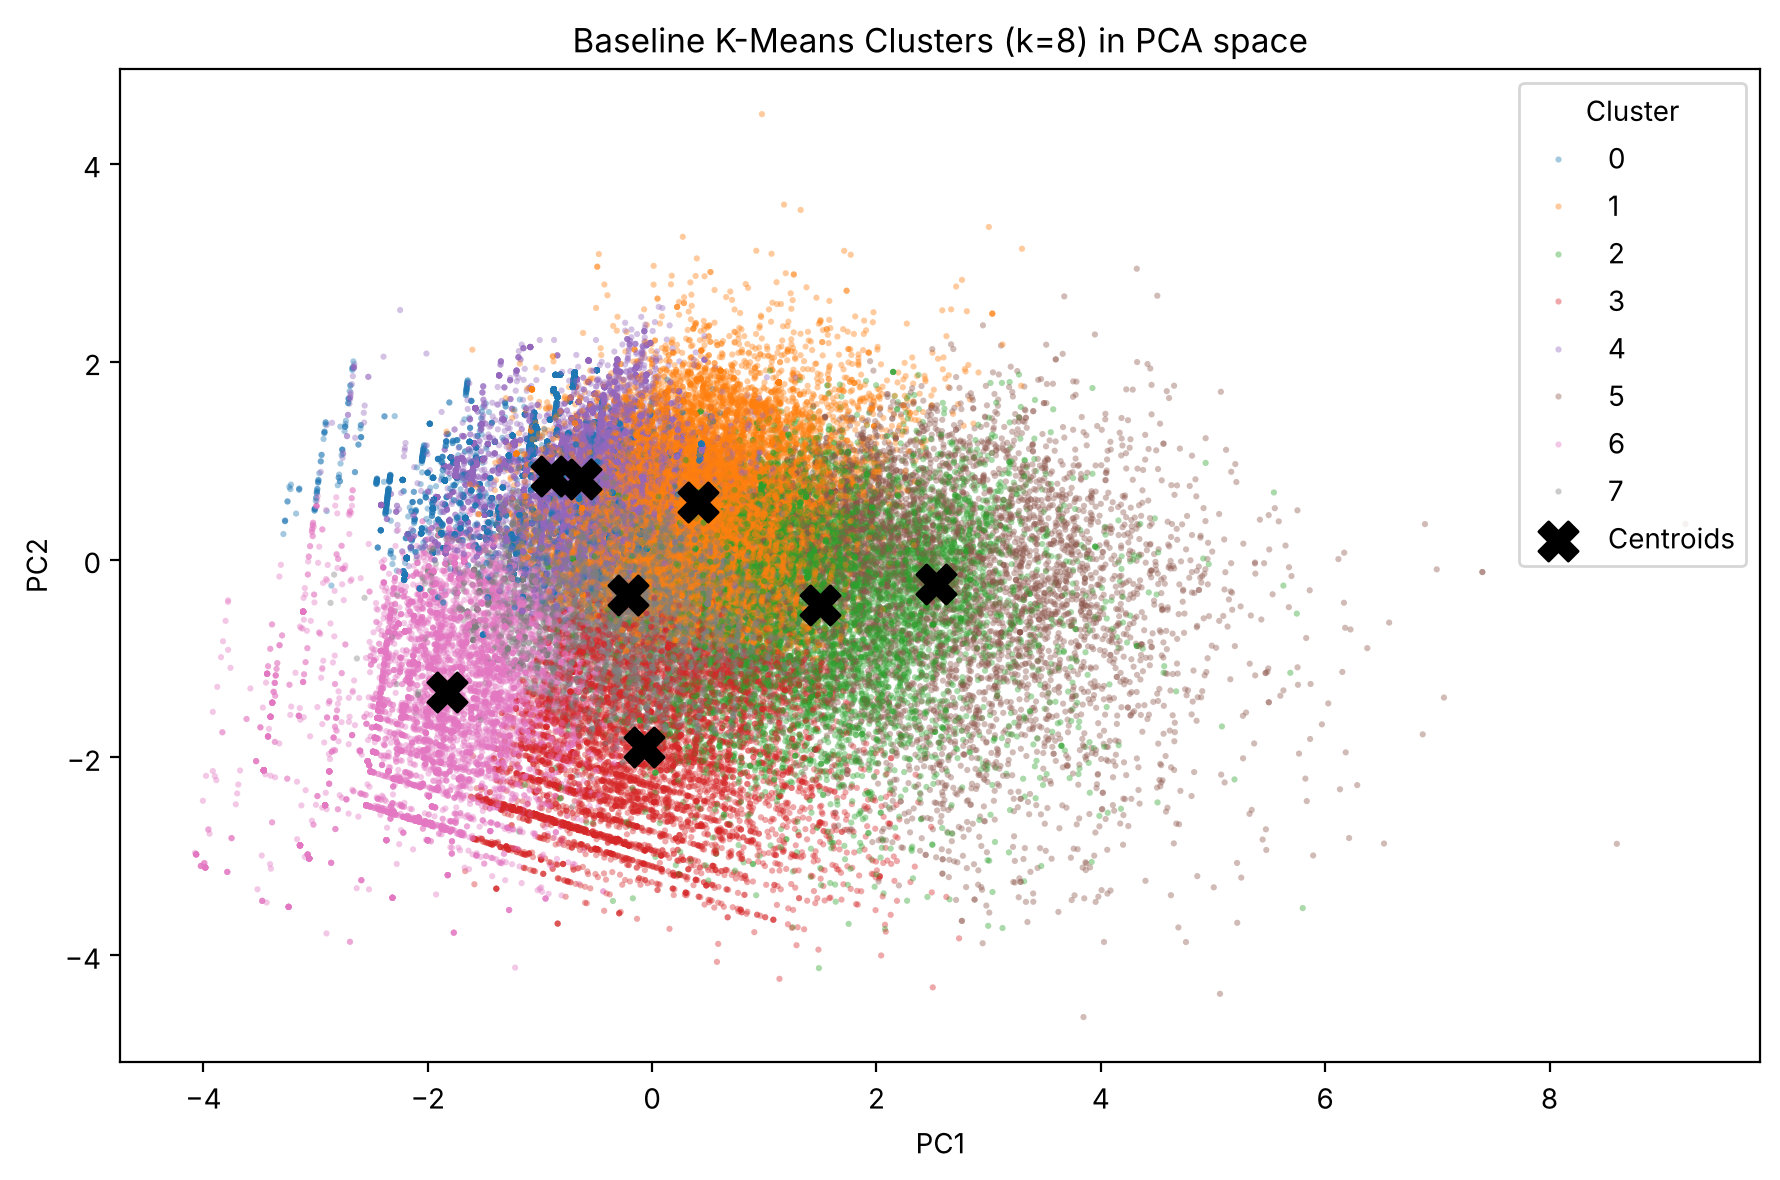

In [17]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X)
print("Explained variance by 2 components:", pca.explained_variance_ratio_.sum().round(3))

centers_2d = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=kmeans.labels_, palette="tab10", s=5, alpha=0.4, linewidth=0)
plt.scatter(centers_2d[:, 0], centers_2d[:, 1], c="black", marker="X", s=200, label="Centroids")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Baseline K-Means Clusters (k={kmeans.n_clusters}) in PCA space")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## Cluster Interpretation
Profiles use the **original (unscaled, un-logged)** values so they are easy to read.

In [18]:
df["Cluster"] = kmeans.labels_

profile = df.groupby("Cluster")[num_cols].mean().round(1)
profile["Size"] = df["Cluster"].value_counts().sort_index()
profile["Share %"] = (profile["Size"] / len(df) * 100).round(1)
profile["Top MarketSegment"] = df.groupby("Cluster")["MarketSegment"].agg(lambda s: s.value_counts().index[0])
profile

,LeadTime,TotalNights,ADR,TotalGuests,TotalOfSpecialRequests,Size,Share %,Top MarketSegment
Cluster,,,,,,,,
0,215.9,2.4,79.3,1.8,0.1,12090,15.3,Groups
1,98.7,4.6,108.2,2.0,0.5,17489,22.2,Online TA
2,95.4,3.5,116.1,2.2,2.2,7918,10.0,Online TA
3,4.3,1.9,123.2,1.9,0.6,6715,8.5,Online TA
4,153.2,3.1,91.5,1.8,0.1,12649,16.0,Offline TA/TO
5,85.7,3.3,178.6,3.3,0.7,6099,7.7,Online TA
6,12.9,1.7,73.4,1.1,0.3,7215,9.1,Corporate
7,113.7,1.5,109.0,1.9,0.5,8760,11.1,Online TA


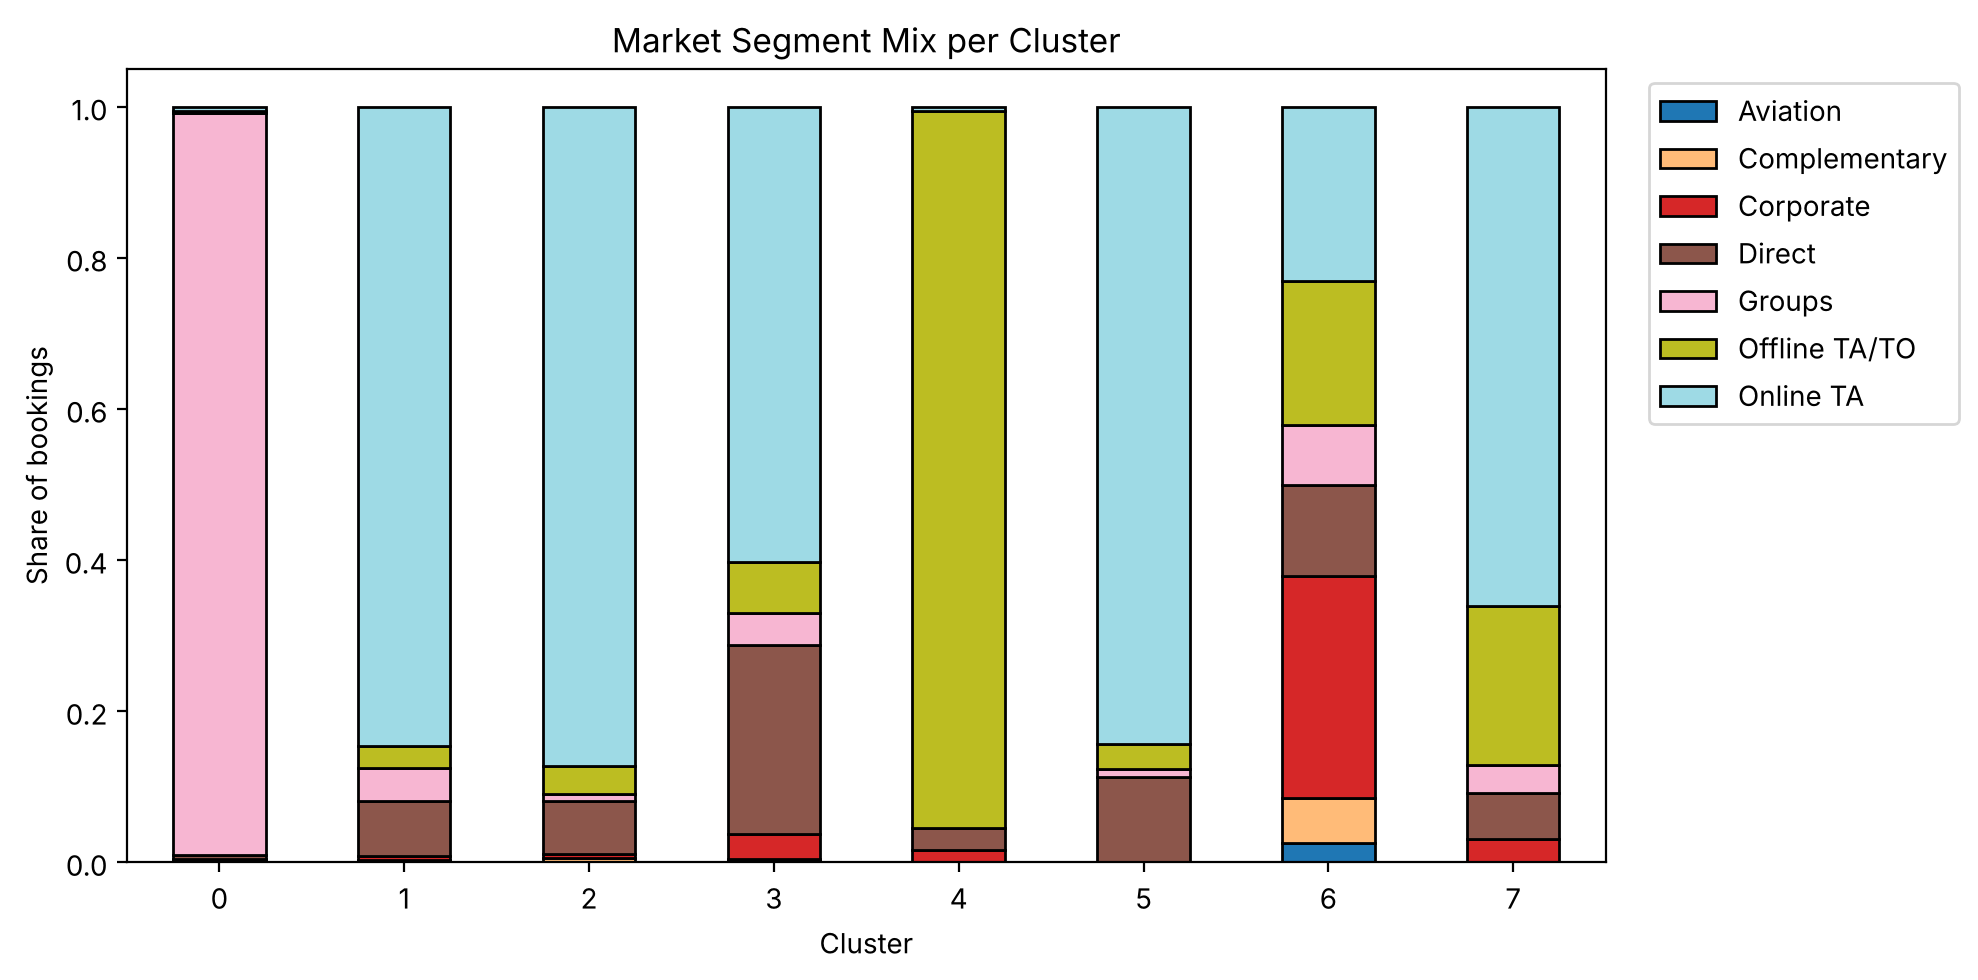

In [19]:
seg = pd.crosstab(df["Cluster"], df["MarketSegment"], normalize="index")
seg.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20", edgecolor="black")
plt.ylabel("Share of bookings")
plt.title("Market Segment Mix per Cluster")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

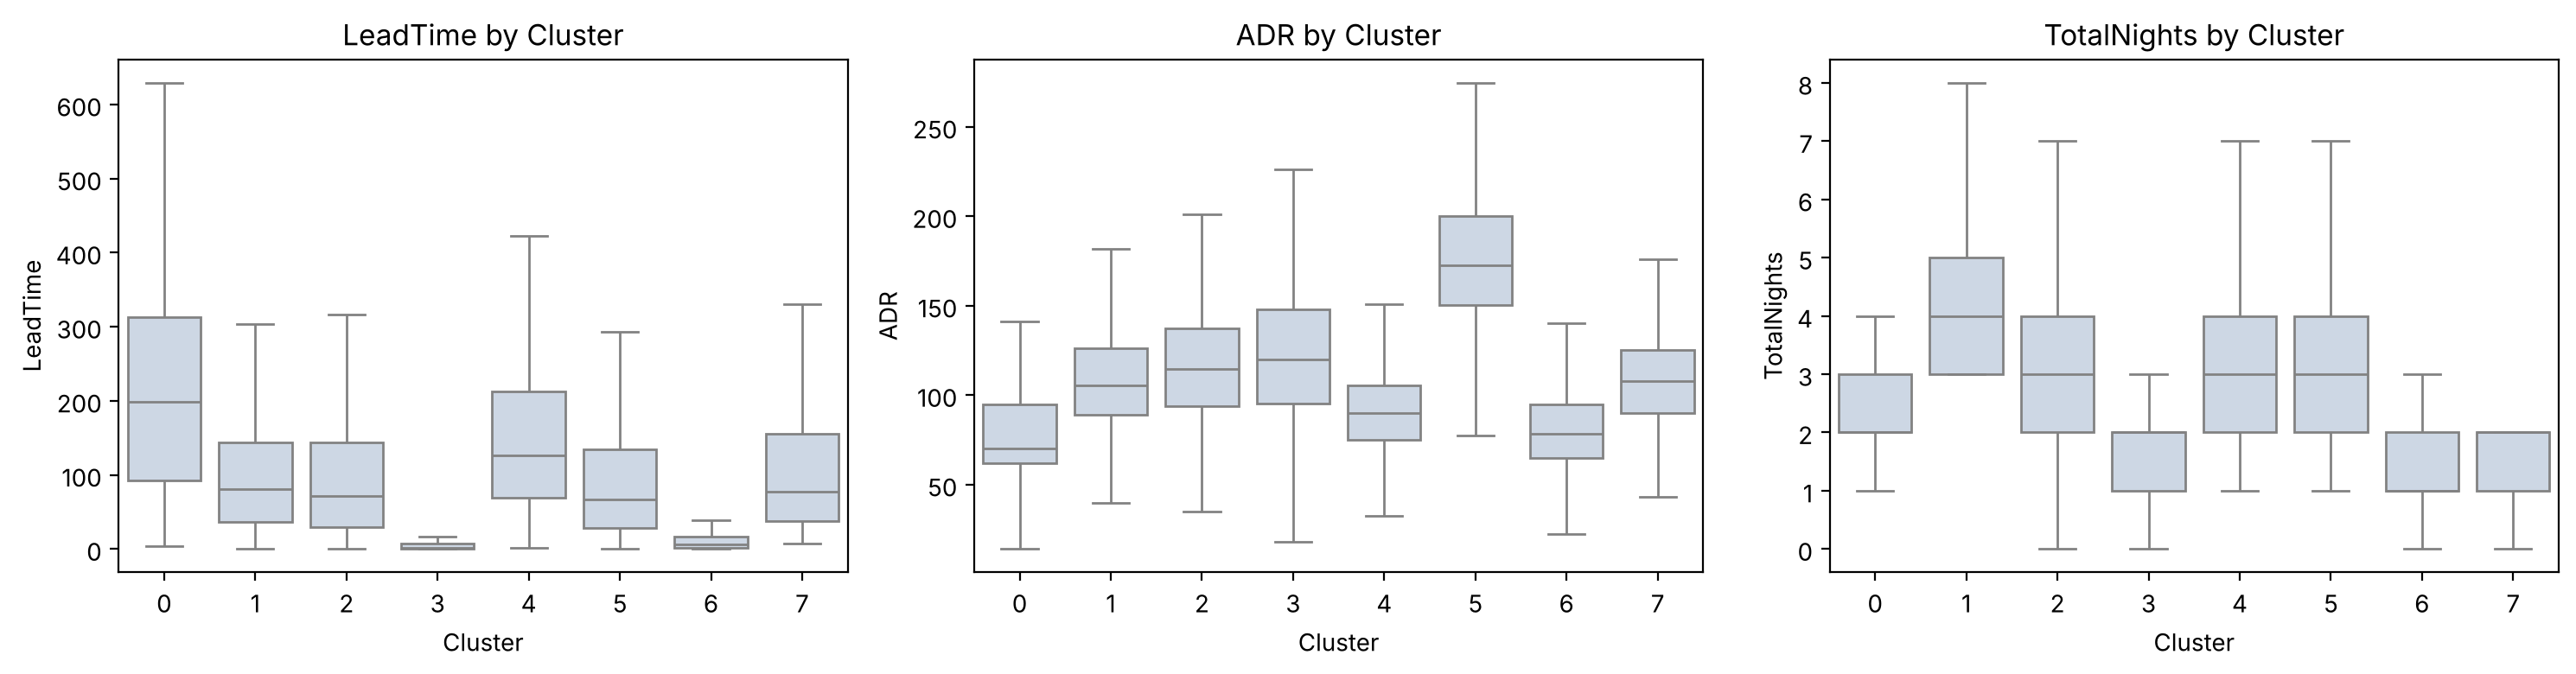

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["LeadTime", "ADR", "TotalNights"]):
    sns.boxplot(data=df, x="Cluster", y=c, ax=ax, showfliers=False, color="#C9D6E8")
    ax.set_title(f"{c} by Cluster")
plt.tight_layout()
plt.show()

### Post-hoc check (not used for training)
After the clusters are fixed, the cancellation rate per cluster is shown only to describe the segments. `IsCanceled` played no part in fitting the model.

In [21]:
df.groupby("Cluster")["IsCanceled"].mean().round(3).to_frame("Cancellation Rate")

,Cancellation Rate
Cluster,
0,0.724
1,0.427
2,0.220
3,0.157
4,0.483
5,0.430
6,0.192
7,0.439


### What the baseline clusters mean
(Cluster numbers come from `random_state=42`; another scikit-learn version may number them differently, so read them by profile.)

| Cluster | Segment | Key traits | Post-hoc cancel rate |
|---|---|---|---|
| 0 | **Group bookings, booked very early** | 98% Groups, lead time ~216 days, low ADR (~79), 58% non-refundable deposit | ~72% |
| 1 | **Online longer stays** | 85% Online TA, longest stays (~4.6 nights), average price | ~43% |
| 2 | **Online guests with many special requests** | 87% Online TA, ~2.2 special requests per booking | ~22% |
| 3 | **Last-minute bookers** | booked ~4 days ahead, short stays, more Direct bookings (25%) | ~16% |
| 4 | **Tour operator bookings** | 95% Offline TA/TO, long lead time (~153 days), low ADR, 34% non-refundable | ~48% |
| 5 | **Families** | ~3.3 guests, half include children, highest ADR (~179) | ~43% |
| 6 | **Solo business travellers** | ~1.1 guests, 1 to 2 nights, booked ~13 days ahead, mostly Corporate, most repeat guests (19%) | ~19% |
| 7 | **Online short stays** | ~1.5 nights, mostly Online TA, average lead time and price | ~44% |

**Observations**
- Some clusters are clearly distinct (Groups, Tour operators, Families, Solo business), and they match the cancellation patterns seen in the classification EDA.
- Clusters 1, 2 and 7 are all mainly Online TA bookings and differ only in stay length or requests, so 8 clusters looks like more than the data naturally supports. This fits the low Silhouette Score (~0.18).
- **Next step (Milestone 2):** tune the number of clusters with the elbow method, Silhouette and Davies-Bouldin, and compare the tuned model to this baseline.

## Save the Model
The fitted preprocessing + K-Means are saved as one pipeline so new bookings can be assigned to a cluster without retraining.  
Note: the `log1p` step on `LeadTime` and `TotalNights` must be applied to new data before calling `predict`.

In [22]:
import os
import joblib

kmeans_pipeline = Pipeline(steps=[
    ('preprocessor', processor),
    ('kmeans', kmeans),
])

os.makedirs("../artifacts", exist_ok=True)
joblib.dump(kmeans_pipeline, "../artifacts/kmeans_pipeline.joblib")

['../artifacts/kmeans_pipeline.joblib']

In [23]:
# quick check: load the saved pipeline and assign clusters to a few bookings
# (df_clust already has the log1p columns, same format the pipeline was trained on)
loaded = joblib.load("../artifacts/kmeans_pipeline.joblib")
loaded.predict(df_clust[num_cols + cat_cols].head())

array([6, 1, 1, 2, 7], dtype=int32)